# Chapitre 11 - Cours 1 : projection pursuit regression et passage aux réseaux de neurones

Ce premier notebook couvre les sections 11.1 à 11.3 du livre :

1. l'idée commune aux méthodes du chapitre : construire des **variables dérivées**, combinaisons
   linéaires des entrées, puis modéliser la réponse comme une fonction **non linéaire** de
   ces variables ;
2. le modèle de **projection pursuit regression** (PPR, éq. (11.1)) et les **fonctions ridge**
   (figure 11.1) ;
3. l'ajustement de la PPR : lissage par spline et étape de **Gauss–Newton** (éq. (11.2)–(11.4)) ;
4. le **réseau de neurones à une couche cachée** (éq. (11.5)–(11.7), figures 11.2 et 11.3), vu
   comme une PPR dont les fonctions ridge sont des sigmoïdes paramétrées.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from esl.plotting import set_style, COLORS, BLUE, ORANGE, GRAY, SEQ, DIV, TWO_CLASS
set_style()

from esl.ch11_reseaux import PPR, SmoothingSpline, sigmoid

## 1. Le modèle de projection pursuit regression

On dispose d'un vecteur d'entrées $X \in \mathbb{R}^p$ et d'une réponse quantitative $Y$.
Soient $\omega_1, \dots, \omega_M$ des vecteurs **unitaires** de $\mathbb{R}^p$ (inconnus,
$\|\omega_m\| = 1$). Le modèle PPR s'écrit

$$f(X) = \sum_{m=1}^{M} g_m(\omega_m^T X) \qquad \text{(éq. (11.1) du livre).}$$

C'est un **modèle additif** (chapitre 9), mais additif en les **variables dérivées**
$V_m = \omega_m^T X$ et non en les entrées $X_j$ elles-mêmes. Les fonctions
$g_m : \mathbb{R} \to \mathbb{R}$ ne sont pas spécifiées à l'avance : elles sont estimées
en même temps que les directions $\omega_m$.

### Fonctions ridge

Une fonction de la forme $x \mapsto g(\omega^T x)$ s'appelle une **fonction ridge** (« fonction
crête »). Le nombre $V = \omega^T x$ est la **projection** de $x$ sur la droite dirigée par le
vecteur unitaire $\omega$.

> **Intuition.** Une fonction ridge ne varie que dans **une seule direction**, celle de $\omega$.
> Si l'on se déplace orthogonalement à $\omega$, c'est-à-dire de $x$ à $x + u$ avec
> $\omega^T u = 0$, la projection ne change pas : $\omega^T(x+u) = \omega^T x$, donc
> $g(\omega^T(x+u)) = g(\omega^T x)$. Le graphe ressemble à une « tôle ondulée » dont les plis
> sont orthogonaux à $\omega$.

La figure 11.1 du livre montre deux fonctions ridge sur $\mathbb{R}^2$ :

* à gauche, $g(V) = 1/[1 + \exp(-5(V - 0{,}5))]$ avec $V = (X_1 + X_2)/\sqrt{2}$, soit
  $\omega = (1, 1)^T/\sqrt 2$ ;
* à droite, $g(V) = (V + 0{,}1)\sin\big(1/(V/3 + 0{,}1)\big)$ avec $V = X_1$, soit $\omega = (1, 0)^T$.

Les entrées sont prises dans le carré $[0,1]^2$.

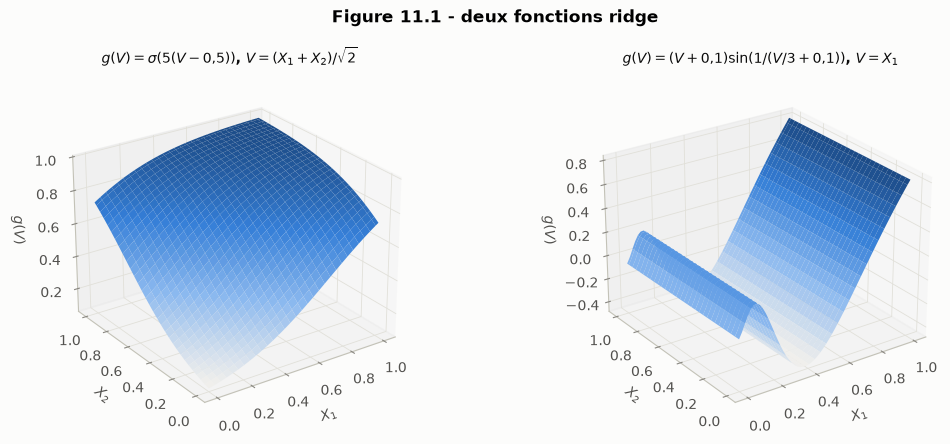

In [2]:
grid = np.linspace(0, 1, 60)
X1, X2 = np.meshgrid(grid, grid)
G_left = 1 / (1 + np.exp(-5 * ((X1 + X2) / np.sqrt(2) - 0.5)))
G_right = (X1 + 0.1) * np.sin(1 / (X1 / 3 + 0.1))

fig = plt.figure(figsize=(11, 4.5))
for j, (G, titre) in enumerate([(G_left, r"$g(V)=\sigma(5(V-0{,}5))$, $V=(X_1+X_2)/\sqrt{2}$"),
                                (G_right, r"$g(V)=(V+0{,}1)\sin(1/(V/3+0{,}1))$, $V=X_1$")]):
    ax = fig.add_subplot(1, 2, j + 1, projection="3d")
    ax.plot_surface(X1, X2, G, cmap=SEQ, linewidth=0, antialiased=True, alpha=0.95)
    ax.set_xlabel("$X_1$")
    ax.set_ylabel("$X_2$")
    ax.set_zlabel("$g(V)$")
    ax.set_title(titre, fontsize=10)
    ax.view_init(elev=25, azim=-125)
fig.suptitle("Figure 11.1 - deux fonctions ridge", fontweight="bold")
plt.tight_layout()
plt.show()

Vérifions numériquement l'invariance : pour la fonction de gauche, un déplacement le long de
$u = (1, -1)^T$ (orthogonal à $\omega$) ne change pas la valeur.

In [3]:
def g_left(x1, x2):
    return 1 / (1 + np.exp(-5 * ((x1 + x2) / np.sqrt(2) - 0.5)))

rng = np.random.RandomState(0)
pts = rng.uniform(0, 1, (5, 2))
t = rng.uniform(-0.3, 0.3, 5)
print("g(x)         :", np.round(g_left(pts[:, 0], pts[:, 1]), 6))
print("g(x + t*u)   :", np.round(g_left(pts[:, 0] + t, pts[:, 1] - t), 6))

g(x)         : [0.877496 0.826001 0.782692 0.900249 0.905743]
g(x + t*u)   : [0.877496 0.826001 0.782692 0.900249 0.905743]


### Un modèle très riche : l'exemple du produit

Former des fonctions non linéaires de combinaisons linéaires engendre une classe de modèles
étonnamment vaste. Par exemple, le produit $X_1 X_2$ (qui n'est **pas** additif en $X_1$ et
$X_2$) est une somme de deux fonctions ridge. En effet, en développant les carrés,

$$
\begin{aligned}
(X_1 + X_2)^2 - (X_1 - X_2)^2
&= (X_1^2 + 2X_1X_2 + X_2^2) - (X_1^2 - 2X_1X_2 + X_2^2) \\
&= 4 X_1 X_2 ,
\end{aligned}
$$

donc $X_1 X_2 = g_1(\omega_1^T X) + g_2(\omega_2^T X)$ avec $\omega_1 = (1,1)^T/\sqrt2$,
$\omega_2 = (1,-1)^T/\sqrt 2$, $g_1(v) = v^2/2$ et $g_2(v) = -v^2/2$
(car $(X_1+X_2)^2/4 = (\omega_1^TX)^2 \cdot 2/4$).

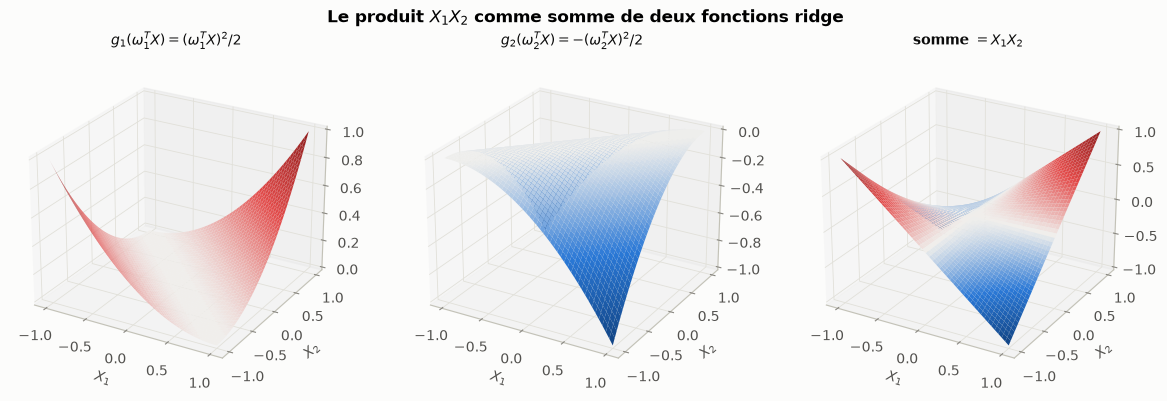

In [4]:
grid = np.linspace(-1, 1, 50)
X1, X2 = np.meshgrid(grid, grid)
V1 = (X1 + X2) / np.sqrt(2)
V2 = (X1 - X2) / np.sqrt(2)
panneaux = [(V1 ** 2 / 2, r"$g_1(\omega_1^TX) = (\omega_1^TX)^2/2$"),
            (-V2 ** 2 / 2, r"$g_2(\omega_2^TX) = -(\omega_2^TX)^2/2$"),
            (V1 ** 2 / 2 - V2 ** 2 / 2, r"somme $= X_1X_2$")]
fig = plt.figure(figsize=(12, 4))
for j, (G, titre) in enumerate(panneaux):
    ax = fig.add_subplot(1, 3, j + 1, projection="3d")
    ax.plot_surface(X1, X2, G, cmap=DIV, vmin=-1, vmax=1, linewidth=0)
    ax.set_xlabel("$X_1$")
    ax.set_ylabel("$X_2$")
    ax.set_title(titre, fontsize=10)
    ax.view_init(elev=25, azim=-60)
fig.suptitle("Le produit $X_1X_2$ comme somme de deux fonctions ridge", fontweight="bold")
plt.tight_layout()
plt.show()

In [5]:
print("écart maximal entre la somme des deux ridges et X1*X2 :",
      np.max(np.abs(V1 ** 2 / 2 - V2 ** 2 / 2 - X1 * X2)))

écart maximal entre la somme des deux ridges et X1*X2 : 3.3306690738754696e-16


> **Remarque (approximation universelle).** Plus généralement, si $M$ peut être aussi grand que
> l'on veut et si les $g_m$ sont bien choisies, le modèle PPR approche **n'importe quelle
> fonction continue** sur un compact de $\mathbb{R}^p$ avec une précision arbitraire. On dit que
> c'est un **approximateur universel**. Le prix à payer est l'**interprétabilité** : chaque
> entrée intervient dans plusieurs termes, de façon non linéaire. Le cas $M = 1$ (le *single
> index model* des économètres) fait exception : il généralise légèrement la régression
> linéaire et s'interprète de la même façon.

## 2. Ajustement de la PPR

Étant données des observations $(x_i, y_i)$, $i = 1, \dots, N$, on cherche à minimiser
(approximativement) l'erreur quadratique

$$\sum_{i=1}^N \Big[y_i - \sum_{m=1}^M g_m(\omega_m^T x_i)\Big]^2 \qquad \text{(éq. (11.2))}$$

en les fonctions $g_m$ et les directions $\omega_m$. Comme pour tout problème de lissage, il
faut contraindre la complexité des $g_m$ : sinon une fonction qui interpole les données donne
une erreur nulle, ce qui est un sur-ajustement.

Considérons d'abord **un seul terme** ($M = 1$, on omet l'indice). L'idée est d'**alterner**
deux étapes faciles : estimer $g$ à $\omega$ fixé, puis $\omega$ à $g$ fixée.

### Étape 1 : $\omega$ fixé, estimation de $g$ par lissage

Si $\omega$ est connu, on forme les variables dérivées $v_i = \omega^T x_i$ et l'on doit
ajuster une fonction d'**une seule** variable au nuage $(v_i, y_i)$ : c'est un problème de
lissage unidimensionnel. Nous utilisons une **spline de lissage** (chapitre 5), qui minimise

$$\sum_{i=1}^N \big(y_i - g(v_i)\big)^2 + \lambda \int g''(t)^2\, dt .$$

Rappels utiles :

* la solution est une spline cubique naturelle à nœuds aux $v_i$ ; le vecteur des valeurs
  ajustées est linéaire en $y$ : $\hat{\mathbf g} = S_\lambda \mathbf y$ avec
  $S_\lambda = (I + \lambda K)^{-1}$, où $K$ est une matrice symétrique positive qui ne dépend que
  des $v_i$ (elle vérifie $\mathbf g^T K \mathbf g = \int g''^2$) ;
* on mesure la complexité par le **nombre de degrés de liberté effectifs**
  $\mathrm{df}_\lambda = \mathrm{tr}(S_\lambda)$, qui décroît de $N$ (interpolation, $\lambda=0$)
  à $2$ (droite des moindres carrés, $\lambda \to \infty$).

Notre classe `SmoothingSpline` choisit $\lambda$ de façon à atteindre un $\mathrm{df}$ fixé ; elle
fournit aussi la **dérivée** $g'$, dont nous aurons besoin à l'étape 2.

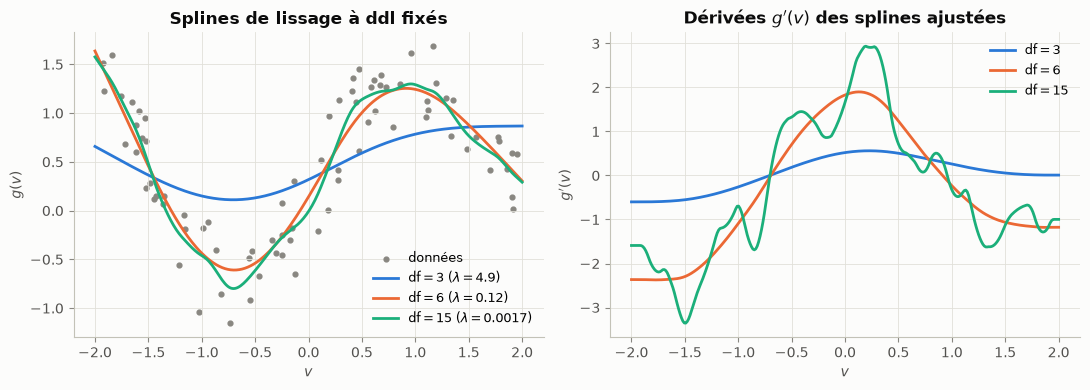

In [6]:
rng = np.random.RandomState(0)
v = np.sort(rng.uniform(-2, 2, 80))
yv = np.sin(2 * v) + 0.3 * v ** 2 + 0.3 * rng.randn(80)
vv = np.linspace(-2, 2, 300)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(v, yv, s=12, color=GRAY, label="données")
for c, df in zip(COLORS, [3, 6, 15]):
    ss = SmoothingSpline(df=df).fit(v, yv)
    axes[0].plot(vv, ss.predict(vv), color=c, label=r"$\mathrm{df}=%d$ ($\lambda=%.2g$)" % (df, ss.lam_))
    axes[1].plot(vv, ss.derivative(vv), color=c, label=r"$\mathrm{df}=%d$" % df)
axes[0].set_title("Splines de lissage à ddl fixés")
axes[0].set_xlabel("$v$")
axes[0].set_ylabel("$g(v)$")
axes[0].legend()
axes[1].set_title("Dérivées $g'(v)$ des splines ajustées")
axes[1].set_xlabel("$v$")
axes[1].set_ylabel("$g'(v)$")
axes[1].legend()
plt.tight_layout()
plt.show()

### Étape 2 : $g$ fixée, mise à jour de $\omega$ par Gauss–Newton

Il faut maintenant minimiser $\sum_i [y_i - g(\omega^T x_i)]^2$ en $\omega$. Ce n'est pas un
problème de moindres carrés linéaires, car $\omega$ est « à l'intérieur » de $g$. La méthode de
**Gauss–Newton** consiste à **linéariser** $g$ autour de l'estimation courante
$\omega_{\text{old}}$ : par un développement de Taylor à l'ordre 1 de $g$ au point
$\omega_{\text{old}}^T x_i$,

$$g(\omega^T x_i) \approx g(\omega_{\text{old}}^T x_i) + g'(\omega_{\text{old}}^T x_i)\,(\omega - \omega_{\text{old}})^T x_i
\qquad \text{(éq. (11.3))}.$$

(On a écrit $\omega^T x_i = \omega_{\text{old}}^T x_i + (\omega - \omega_{\text{old}})^T x_i$.)

Notons $v_i = \omega_{\text{old}}^T x_i$, $g_i = g(v_i)$ et $g'_i = g'(v_i)$. On reporte
l'approximation dans chaque terme de l'erreur :

$$
\begin{aligned}
y_i - g(\omega^T x_i)
&\approx y_i - g_i - g'_i\,(\omega^T x_i - v_i) \\
&= g'_i \Big[ \frac{y_i - g_i}{g'_i} + v_i - \omega^T x_i \Big] \qquad (\text{on factorise } g'_i \ne 0).
\end{aligned}
$$

En élevant au carré et en sommant :

$$\sum_{i=1}^N \big[y_i - g(\omega^T x_i)\big]^2 \approx \sum_{i=1}^N (g'_i)^2
\Big[\underbrace{\omega_{\text{old}}^T x_i + \frac{y_i - g_i}{g'_i}}_{\text{cible } z_i} - \omega^T x_i\Big]^2
\qquad \text{(éq. (11.4))}.$$

Le membre de droite est un critère de **moindres carrés pondérés** : on régresse la cible
$z_i = \omega_{\text{old}}^T x_i + (y_i - g_i)/g'_i$ sur les entrées $x_i$, avec les poids
$w_i = (g'_i)^2$ et **sans constante** (la constante est déjà absorbée par $g$). La solution
fournit $\omega_{\text{new}}$, que l'on renormalise pour qu'il soit unitaire.

> **Remarque.** On parle de méthode **quasi-Newton** : la méthode de Newton exacte utiliserait la
> matrice hessienne du critère, qui contient un terme en $g''$ ; Gauss–Newton néglige ce terme
> (il est multiplié par les résidus, petits près de la solution) et ne garde que $\sum_i (g'_i)^2 x_i x_i^T$.
> En pratique, notre implémentation évite la division par $g'_i$ : elle résout le problème
> équivalent $\min_\omega \sum_i [g'_i v_i + (y_i - g_i) - g'_i\,\omega^T x_i]^2$, et divise le pas
> par deux tant que l'erreur n'a pas diminué.

### Illustration : un *single index model*

Simulons $Y = \tanh(2\,\omega_\star^T X) + \varepsilon$ avec $X \sim \mathcal N(0, I_3)$,
$\omega_\star = (1, 2, -2)^T/3$ et un bruit d'écart-type $0{,}2$, puis ajustons une PPR à un terme.
Nous suivons l'angle entre $\omega$ et $\omega_\star$ au fil des itérations de l'algorithme
alterné.

In [7]:
rng = np.random.RandomState(0)
N, p = 200, 3
w_star = np.array([1.0, 2.0, -2.0]) / 3
X = rng.randn(N, p)
y = np.tanh(2 * X @ w_star) + 0.2 * rng.randn(N)

def angle_deg(a, b):
    c = abs(a @ b) / (np.linalg.norm(a) * np.linalg.norm(b))
    return np.degrees(np.arccos(np.clip(c, -1, 1)))

Pour bien voir la convergence, nous écrivons la boucle à la main à partir d'une direction
initiale volontairement mauvaise ($\omega_0 = (1, 0, 0)^T$, à environ 70° de $\omega_\star$).

In [8]:
w = np.array([1.0, 0.0, 0.0])
angles, rss = [angle_deg(w, w_star)], []
for it in range(8):
    g = SmoothingSpline(df=5).fit(X @ w, y)                 # étape 1 : lissage
    v_old = X @ w
    gi, dgi = g.predict(v_old), g.derivative(v_old)
    rss.append(np.sum((y - gi) ** 2))
    A = dgi[:, None] * X                                     # étape 2 : Gauss–Newton
    b = dgi * v_old + (y - gi)
    w = np.linalg.lstsq(A, b, rcond=None)[0]
    w /= np.linalg.norm(w)
    angles.append(angle_deg(w, w_star))
print("angle (degrés) :", np.round(angles, 2))
print("RSS            :", np.round(rss, 2))

angle (degrés) : [70.53 17.37  2.49  1.83  1.79  1.78  1.78  1.78  1.78]
RSS            : [120.69  29.4    9.81   9.33   9.32   9.32   9.32   9.33]


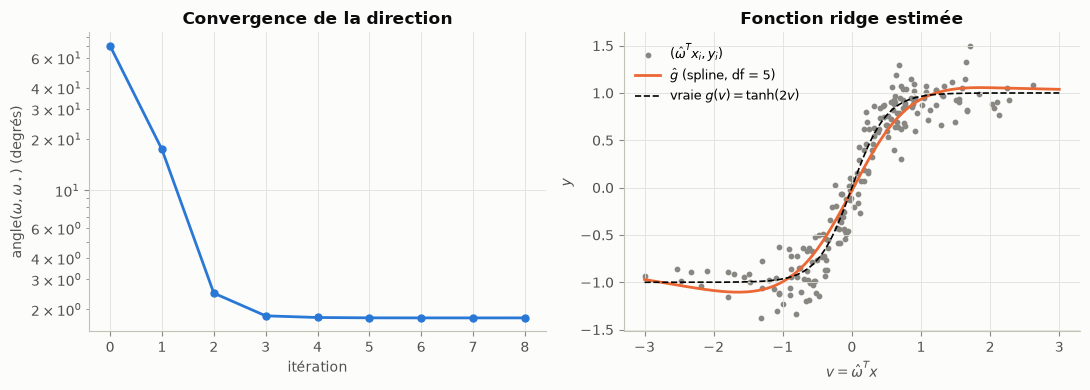

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(angles, "o-", color=BLUE)
axes[0].set_yscale("log")
axes[0].set_xlabel("itération")
axes[0].set_ylabel(r"angle$(\omega, \omega_\star)$ (degrés)")
axes[0].set_title("Convergence de la direction")
vv = np.linspace(-3, 3, 200)
g = SmoothingSpline(df=5).fit(X @ w, y)
axes[1].scatter(X @ w, y, s=10, color=GRAY, label=r"$(\hat\omega^Tx_i, y_i)$")
axes[1].plot(vv, g.predict(vv), color=ORANGE, label=r"$\hat g$ (spline, df = 5)")
axes[1].plot(vv, np.tanh(2 * vv), "--", color="k", lw=1.2, label=r"vraie $g(v)=\tanh(2v)$")
axes[1].set_xlabel(r"$v = \hat\omega^T x$")
axes[1].set_ylabel("$y$")
axes[1].set_title("Fonction ridge estimée")
axes[1].legend()
plt.tight_layout()
plt.show()

En quelques itérations, la direction est retrouvée à une fraction de degré près, et la
fonction $\hat g$ épouse la vraie fonction $\tanh(2v)$.

### Plusieurs termes : construction progressive

Avec $M > 1$, le modèle est construit de façon **progressive** (*forward stagewise*) : à l'étape
$m$, on ajuste un couple $(\omega_m, g_m)$ par l'algorithme alterné ci-dessus aux **résidus**
$r_i = y_i - \sum_{l<m} g_l(\omega_l^T x_i)$, sans toucher aux termes précédents. Quelques
détails de mise en œuvre :

* le lisseur doit fournir des dérivées : splines de lissage ou régression locale conviennent ;
* après chaque étape, on peut réajuster les $g_l$ précédents par **backfitting** (chapitre 9) :
  on cycle sur $l$ en relissant les résidus partiels $y - \sum_{l' \ne l} g_{l'}$ ;
* les directions $\omega_l$ ne sont en général **pas** réajustées (pour limiter les calculs) ;
* le nombre de termes $M$ se choisit en arrêtant quand un terme supplémentaire n'améliore plus
  sensiblement l'ajustement, ou par validation croisée.

Notre classe `PPR` met en œuvre cet algorithme (avec quelques directions initiales par terme et
backfitting optionnel).

### Exemple : somme de deux sigmoïdes

Reprenons le premier modèle simulé de la section 11.6 du livre :

$$Y = \sigma(a_1^T X) + \sigma(a_2^T X) + \varepsilon, \qquad a_1 = (3, 3)^T,\ a_2 = (3, -3)^T,$$

avec $X \sim \mathcal N(0, I_2)$, $\sigma(v) = 1/(1+e^{-v})$ la sigmoïde, et une variance du bruit
choisie pour que le **rapport signal sur bruit** $\mathrm{Var}(f(X))/\mathrm{Var}(\varepsilon)$ vaille 4
(éq. (11.18)). La fonction de régression est **exactement** une PPR à deux termes, de
directions $a_1/\|a_1\|$ et $a_2/\|a_2\|$.

In [10]:
a1, a2 = np.array([3.0, 3.0]), np.array([3.0, -3.0])

def f_sig(X):
    return sigmoid(X @ a1) + sigmoid(X @ a2)

rng = np.random.RandomState(0)
var_f = np.var(f_sig(rng.randn(200_000, 2)))   # Var(f(X)) par Monte-Carlo
sigma2 = var_f / 4                             # RSB = 4
X = rng.randn(100, 2)
y = f_sig(X) + np.sqrt(sigma2) * rng.randn(100)
X_test = rng.randn(10_000, 2)
y_test = f_sig(X_test) + np.sqrt(sigma2) * rng.randn(10_000)
print("Var f(X) = %.4f, variance du bruit = %.4f" % (var_f, sigma2))

Var f(X) = 0.3272, variance du bruit = 0.0818


On ajuste des PPR à $M = 1, \dots, 4$ termes (splines à 5 ddl) et on rapporte l'erreur de test
**relative à l'erreur de Bayes** $\sigma^2$ (la meilleure erreur quadratique possible, celle de
la vraie fonction $f$). Une erreur relative de 1 est donc optimale ; la constante $\bar y$ obtient
environ $1 + \mathrm{RSB} = 5$.

In [11]:
errs = {}
for M in range(1, 5):
    ppr = PPR(n_terms=M, df=5, random_state=0).fit(X, y)
    errs[M] = np.mean((y_test - ppr.predict(X_test)) ** 2) / sigma2
    print("M = %d : erreur de test relative = %.3f" % (M, errs[M]))

M = 1 : erreur de test relative = 1.753


M = 2 : erreur de test relative = 1.480


M = 3 : erreur de test relative = 1.248


M = 4 : erreur de test relative = 1.217


L'erreur diminue jusqu'à $M = 3$ puis se stabilise vers 1,2 fois l'erreur de Bayes. Pourtant la
vraie fonction est une PPR à **deux** termes : regardons les directions trouvées.

In [12]:
ppr3 = PPR(n_terms=3, df=5, random_state=0).fit(X, y)
for m, w in enumerate(ppr3.omegas_):
    print("ω_%d = %s ; angle avec a1 : %5.1f°, avec a2 : %5.1f°"
          % (m + 1, np.round(w, 3), angle_deg(w, a1), angle_deg(w, a2)))

ω_1 = [0.997 0.071] ; angle avec a1 :  40.9°, avec a2 :  49.1°
ω_2 = [0.573 0.82 ] ; angle avec a1 :  10.0°, avec a2 :  80.0°
ω_3 = [ 0.53  -0.848] ; angle avec a1 :  77.0°, avec a2 :  13.0°
